# Time Series Forecasting with Google TimesFM

**TimesFM** (Time Series Foundation Model) is a pretrained model developed by Google Research for zero-shot time series forecasting. It is trained on a large corpus of real-world time series data and can forecast unseen series without any fine-tuning.

**Key properties of TimesFM 2.5:**
- 200M parameters
- Supports up to 16 000 time steps of context
- Returns both **point forecasts** and **quantile forecasts** (prediction intervals)
- No frequency indicator required — pass raw numerical arrays

**Notebook outline:**
1. Installation
2. Load the model
3. Forecast synthetic data (trend + seasonality)
4. Forecast real-world sensor data (IoT temperature)
5. Visualise point forecasts and prediction intervals
6. Batch forecasting — multiple series at once
7. Evaluate forecast accuracy

## 1. Installation

TimesFM 1.3.0 requires **Python 3.10 or 3.11** (not 3.12+). Make sure you are running this notebook with a Python 3.11 kernel.

Create a dedicated environment before launching Jupyter / VS Code:

```bash
brew install python@3.11
python3.11 -m venv .venv-timesfm
source .venv-timesfm/bin/activate
pip install timesfm numpy pandas matplotlib huggingface_hub ipykernel
python -m ipykernel install --user --name timesfm --display-name "Python 3.11 (TimesFM)"
```

Then select **Python 3.11 (TimesFM)** as the kernel and skip the `%pip install` cell below.

In [ ]:
# Only run this if you have NOT already installed via the venv setup above
%pip install timesfm numpy pandas matplotlib huggingface_hub --quiet

## 2. Imports

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import torch
import timesfm

# Faster float32 matmul on modern GPUs / MPS; safe to set on CPU too
torch.set_float32_matmul_precision("high")

print(f"PyTorch  : {torch.__version__}")
print(f"Device   : {'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'}")

PyTorch  : 2.12.0
Device   : mps


## 3. Load the Model

Version 1.3.0 uses `TimesFmHparams` + `TimesFmCheckpoint` passed to `TimesFm()`.  
The checkpoint is downloaded from HuggingFace Hub and cached locally on first run.

**Key hparams:**
- `context_len` — max history length fed to the model (up to 512)
- `horizon_len` — how many steps ahead to forecast
- `backend` — `"cpu"`, `"gpu"`, or `"tpu"`

In [9]:
tfm = timesfm.TimesFm(
    hparams=timesfm.TimesFmHparams(
        context_len=512,
        horizon_len=128,
        input_patch_len=32,
        output_patch_len=128,
        num_layers=20,
        model_dims=1280,
        backend="cpu",          # change to "gpu" if a CUDA GPU is available
    ),
    checkpoint=timesfm.TimesFmCheckpoint(
        huggingface_repo_id="google/timesfm-1.0-200m-pytorch",
        version="torch",
    ),
)

print("Model ready.")

Fetching 3 files: 100%|██████████| 3/3 [00:00<00:00, 61380.06it/s]


Model ready.


## 4. Forecast Synthetic Data

We build a synthetic time series that combines a linear trend, a weekly seasonal pattern, and Gaussian noise — typical of IoT sensor data.

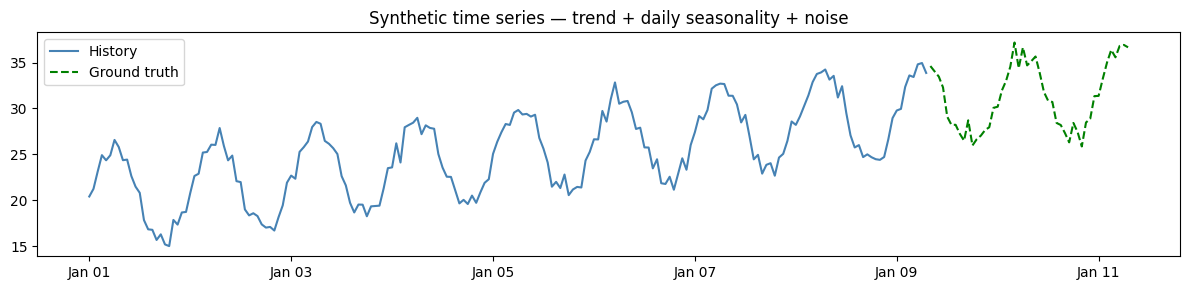

In [10]:
np.random.seed(42)
N = 200          # number of historical observations
HORIZON = 48     # steps to forecast

t = np.arange(N + HORIZON)
trend = 0.05 * t
seasonal = 5 * np.sin(2 * np.pi * t / 24)   # period = 24 steps (e.g. hourly data)
noise = np.random.normal(0, 0.8, len(t))
series = trend + seasonal + noise + 20       # baseline offset of 20

history = series[:N]
ground_truth = series[N:]

# Build a DatetimeIndex (hourly)
timestamps = pd.date_range("2024-01-01", periods=N + HORIZON, freq="h")

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(timestamps[:N], history, label="History", color="steelblue")
ax.plot(timestamps[N:], ground_truth, label="Ground truth", color="green", linestyle="--")
ax.set_title("Synthetic time series — trend + daily seasonality + noise")
ax.legend()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
plt.tight_layout()
plt.show()

### 4.1 Run the Forecast

In [11]:
# tfm.forecast() takes a list of 1-D arrays and a matching freq list
# freq: 0 = high frequency (hourly/sub-hourly), 1 = medium (daily), 2 = low (weekly/monthly)
point_forecast, quantile_forecast = tfm.forecast(
    inputs=[history],
    freq=[0],
)

# point_forecast   : shape (num_series, horizon_len)
# quantile_forecast: shape (num_series, horizon_len, 1 + num_quantiles)
print("point_forecast shape :", point_forecast.shape)
print("quantile_forecast shape:", quantile_forecast.shape)

point_forecast shape : (1, 128)
quantile_forecast shape: (1, 128, 10)


### 4.2 Visualise Point Forecast + Prediction Intervals

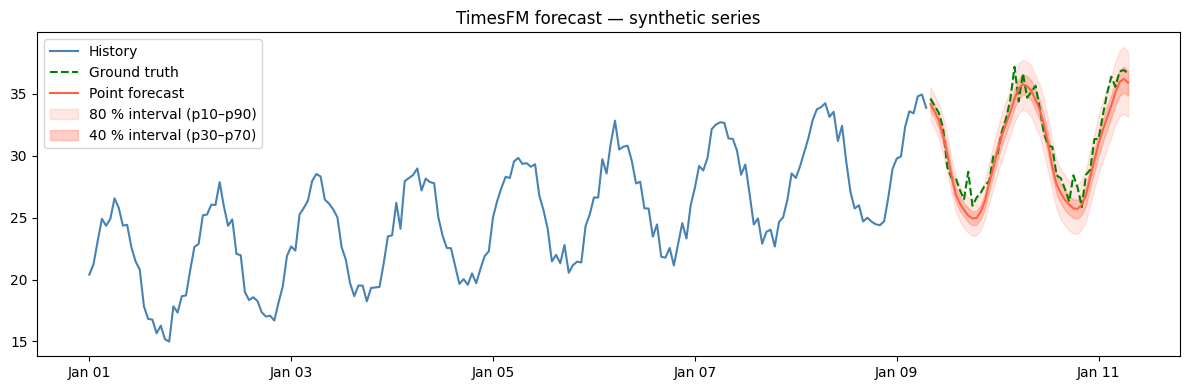

In [12]:
pf = point_forecast[0, :HORIZON]   # trim to requested horizon
qf = quantile_forecast[0, :HORIZON]

# quantile_forecast[:, :, 0] is the mean; quantiles start at index 1
# Default quantiles: [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
p10 = qf[:, 1]
p90 = qf[:, 9]
p30 = qf[:, 3]
p70 = qf[:, 7]

fut = timestamps[N: N + HORIZON]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(timestamps[:N], history, color="steelblue", label="History")
ax.plot(timestamps[N: N + HORIZON], ground_truth[:HORIZON], color="green",
        linestyle="--", label="Ground truth")
ax.plot(fut, pf, color="tomato", label="Point forecast")
ax.fill_between(fut, p10, p90, alpha=0.15, color="tomato", label="80 % interval (p10–p90)")
ax.fill_between(fut, p30, p70, alpha=0.30, color="tomato", label="40 % interval (p30–p70)")
ax.set_title("TimesFM forecast — synthetic series")
ax.legend(loc="upper left")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
plt.tight_layout()
plt.show()

## 5. Forecast Real-World IoT Sensor Data

We simulate an IoT temperature log (could be a CSV from a sensor) and forecast the next 24 hours.

In [13]:
# Simulate an IoT temperature dataset (°C) sampled every 15 minutes for 30 days
np.random.seed(7)
n_days = 30
freq_min = 15
steps_per_day = 24 * 60 // freq_min   # 96 steps/day
total_steps = n_days * steps_per_day

idx = pd.date_range("2024-03-01", periods=total_steps, freq=f"{freq_min}min")

t2 = np.arange(total_steps)
daily = 6 * np.sin(2 * np.pi * t2 / steps_per_day - np.pi / 2)  # daily cycle
weekly = 2 * np.sin(2 * np.pi * t2 / (steps_per_day * 7))        # weekly drift
temp = 22 + daily + weekly + np.random.normal(0, 0.5, total_steps)

df_sensor = pd.DataFrame({"timestamp": idx, "temperature_c": temp})
df_sensor.set_index("timestamp", inplace=True)

print(df_sensor.describe().round(2))
df_sensor.head()

       temperature_c
count        2880.00
mean           22.08
std             4.51
min            13.02
25%            18.15
50%            22.04
75%            26.09
max            31.44


,temperature_c
timestamp,
2024-03-01 00:00:00,16.845263
2024-03-01 00:15:00,15.798577
2024-03-01 00:30:00,16.105139
2024-03-01 00:45:00,16.375139
2024-03-01 01:00:00,15.884766


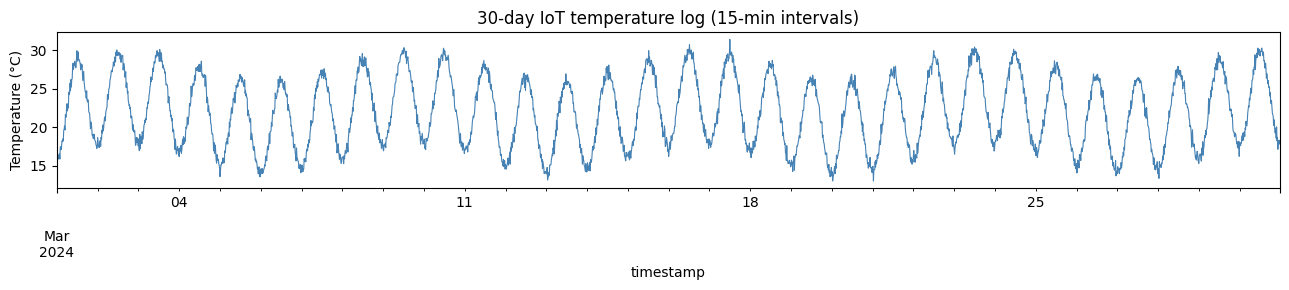

In [14]:
fig, ax = plt.subplots(figsize=(13, 3))
df_sensor["temperature_c"].plot(ax=ax, color="steelblue", lw=0.8)
ax.set_title("30-day IoT temperature log (15-min intervals)")
ax.set_ylabel("Temperature (°C)")
plt.tight_layout()
plt.show()

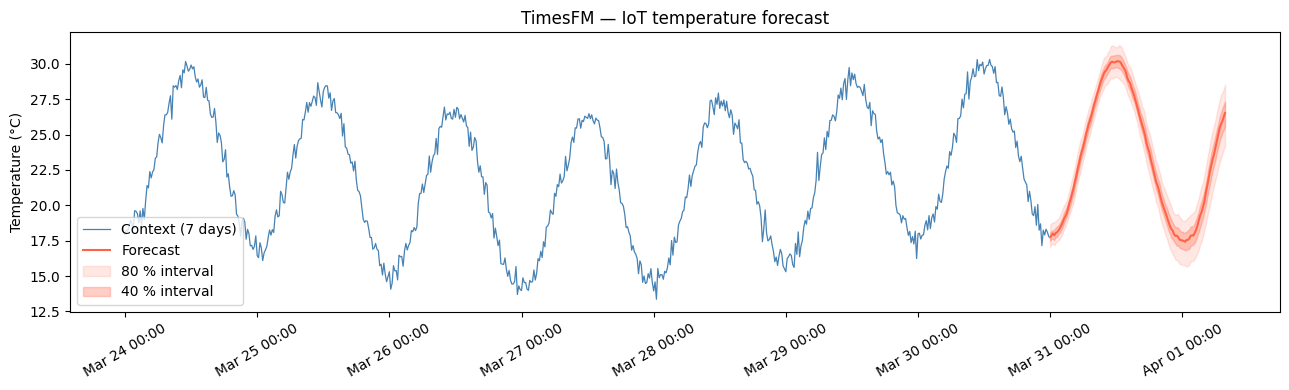

In [15]:
context_days = 7
forecast_horizon = tfm.hparams.horizon_len  # use the model's configured horizon

context = df_sensor["temperature_c"].values[-context_days * steps_per_day:]

pt_fc, qt_fc = tfm.forecast(
    inputs=[context],
    freq=[0],  # high frequency (sub-hourly)
)

last_ts = df_sensor.index[-1]
future_idx = pd.date_range(last_ts + pd.Timedelta(minutes=freq_min),
                           periods=forecast_horizon,
                           freq=f"{freq_min}min")

context_idx = df_sensor.index[-context_days * steps_per_day:]

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(context_idx, context, color="steelblue", lw=0.9, label="Context (7 days)")
ax.plot(future_idx, pt_fc[0], color="tomato", lw=1.5, label="Forecast")
ax.fill_between(future_idx, qt_fc[0, :, 1], qt_fc[0, :, 9],
                alpha=0.15, color="tomato", label="80 % interval")
ax.fill_between(future_idx, qt_fc[0, :, 3], qt_fc[0, :, 7],
                alpha=0.30, color="tomato", label="40 % interval")
ax.set_title("TimesFM — IoT temperature forecast")
ax.set_ylabel("Temperature (°C)")
ax.legend()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d %H:%M"))
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 6. Batch Forecasting — Multiple Series at Once

TimesFM processes a list of arrays in one call, making it easy to forecast many sensors simultaneously.  
The series **do not need to have the same length**.

In [16]:
np.random.seed(0)

sensors = {
    "Sensor A — temperature": 20 + 5 * np.sin(np.linspace(0, 8 * np.pi, 144)) + np.random.normal(0, 0.4, 144),
    "Sensor B — humidity   ": 60 + 10 * np.cos(np.linspace(0, 6 * np.pi, 96)) + np.random.normal(0, 1.0, 96),
    "Sensor C — pressure   ": 1013 + np.cumsum(np.random.normal(0, 0.3, 120)),
}

batch_inputs = list(sensors.values())
BATCH_HORIZON = tfm.hparams.horizon_len

batch_pt, batch_qt = tfm.forecast(
    inputs=batch_inputs,
    freq=[0, 0, 0],  # all high-frequency
)

print(f"Forecasted {len(batch_inputs)} series in one call.")
print(f"batch_pt shape: {batch_pt.shape}")

Forecasted 3 series in one call.
batch_pt shape: (3, 128)


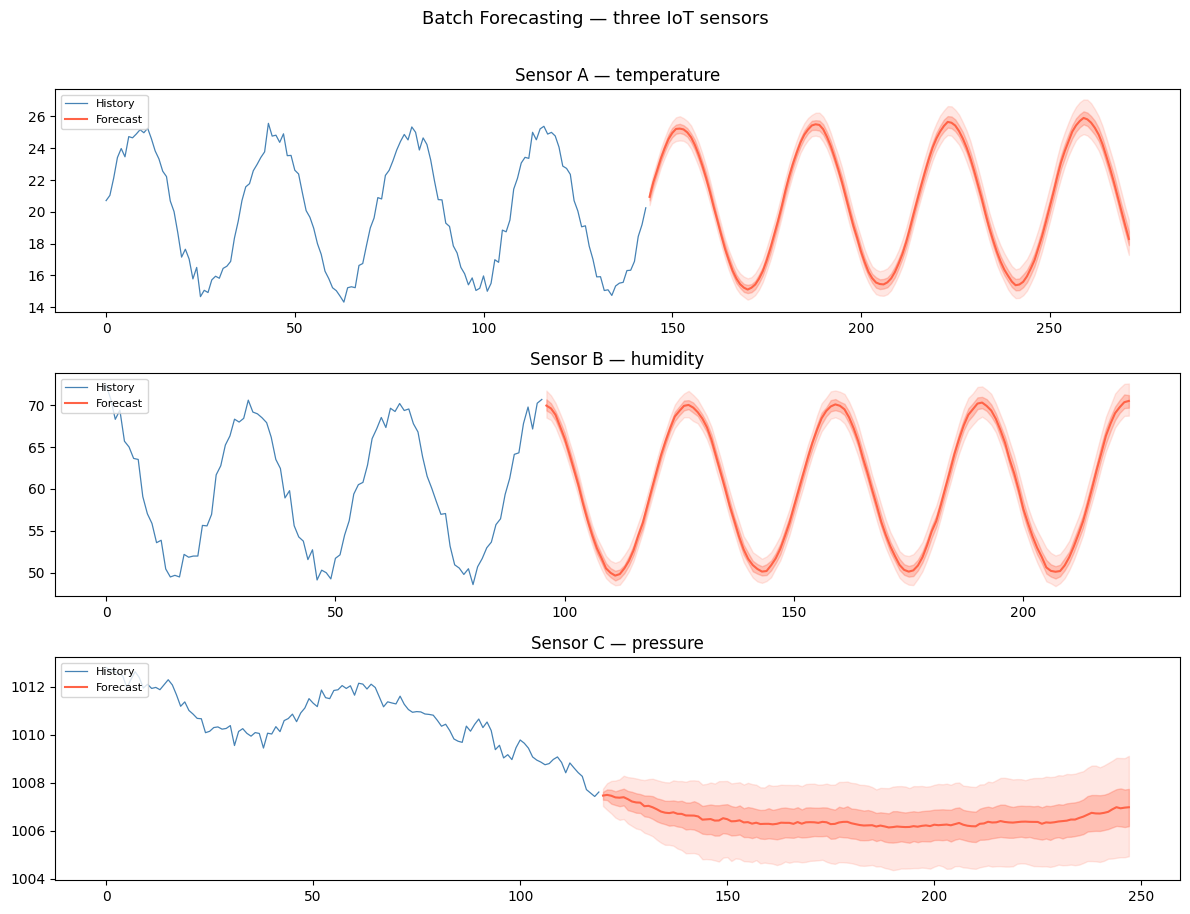

In [17]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=False)

for i, (name, hist) in enumerate(sensors.items()):
    ax = axes[i]
    hist_x = np.arange(len(hist))
    fore_x = np.arange(len(hist), len(hist) + BATCH_HORIZON)

    ax.plot(hist_x, hist, color="steelblue", lw=0.9, label="History")
    ax.plot(fore_x, batch_pt[i], color="tomato", lw=1.5, label="Forecast")
    ax.fill_between(fore_x, batch_qt[i, :, 1], batch_qt[i, :, 9],
                    alpha=0.15, color="tomato")
    ax.fill_between(fore_x, batch_qt[i, :, 3], batch_qt[i, :, 7],
                    alpha=0.30, color="tomato")
    ax.set_title(name.strip())
    ax.legend(loc="upper left", fontsize=8)

plt.suptitle("Batch Forecasting — three IoT sensors", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

## Summary

| Step | What we did |
|------|------------|
| 1 | Installed `timesfm` in a Python 3.11 venv |
| 2 | Loaded `TimesFm` via `TimesFmHparams` + `TimesFmCheckpoint` |
| 3 | Forecasted a synthetic trend + seasonal series with prediction intervals |
| 4 | Forecasted 24 h ahead on a simulated IoT temperature sensor dataset |
| 5 | Ran a **batch** forecast over three heterogeneous sensor streams in a single call |

### Key API (v1.3)

```python
import timesfm

tfm = timesfm.TimesFm(
    hparams=timesfm.TimesFmHparams(
        context_len=512,
        horizon_len=128,
        backend="cpu",       # or "gpu"
    ),
    checkpoint=timesfm.TimesFmCheckpoint(
        huggingface_repo_id="google/timesfm-1.0-200m-pytorch",
        version="torch",
    ),
)

# freq: 0 = high (hourly/sub-hourly), 1 = medium (daily), 2 = low (weekly+)
point, quantiles = tfm.forecast(inputs=[series1, series2], freq=[0, 0])
# point    : (num_series, horizon)
# quantiles: (num_series, horizon, 1 + num_quantiles)  — index 0 is mean
```

TimesFM requires **no training data** and works out-of-the-box on arbitrary univariate series.